c:\Users\sreeh\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.0993 - loss: 3.6871 - val_accuracy: 0.0980 - val_loss: 2.3377
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.1008 - loss: 2.3105 - val_accuracy: 0.0977 - val_loss: 2.3031
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.1005 - loss: 2.3028 - val_accuracy: 0.0952 - val_loss: 2.3028
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.0994 - loss: 2.3027 - val_accuracy: 0.0952 - val_loss: 2.3027
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.0974 - loss: 2.3027 - val_accuracy: 0.0952 - val_loss: 2.3028
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.0991 - loss: 2.3027 - val_accuracy: 0.0977 - val_loss: 2.3027
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.1001 - loss: 2.3027 - val_accuracy: 0.0952 - val_loss: 2.3027
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.0994 - loss: 2.3027 - val_accu

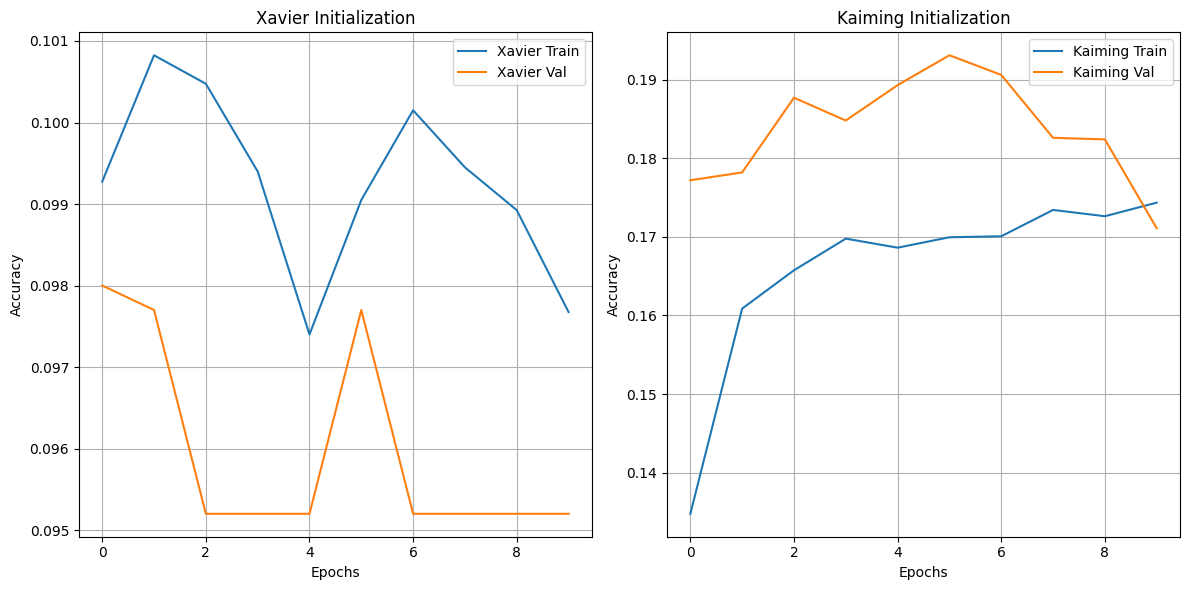

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1000 - loss: 2.3027
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1706 - loss: 2.1702

Xavier Test Accuracy: 10.0%
Kaiming Test Accuracy: 17.06%


In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, initializers, regularizers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train, x_test = x_train / 255.0, x_test / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

def create_model(initializer, dropout_rate=0.3,
                 kernel_regularizer=regularizers.l2(0.01)):
    model = models.Sequential([
        layers.Flatten(input_shape=(32, 32, 3)),
        layers.Dense(
            512,
            activation='relu',
            kernel_initializer=initializer,
            kernel_regularizer=kernel_regularizer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(
            256,
            activation='relu',
            kernel_initializer=initializer,
            kernel_regularizer=kernel_regularizer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(
            128,
            activation='relu',
            kernel_initializer=initializer,
            kernel_regularizer=kernel_regularizer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(
            64,
            activation='relu',
            kernel_initializer=initializer,
            kernel_regularizer=kernel_regularizer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(
            32,
            activation='relu',
            kernel_initializer=initializer,
            kernel_regularizer=kernel_regularizer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(10, activation='softmax')
    ])
    return model

xavier_initializer = initializers.glorot_normal()
kaiming_initializer = initializers.he_normal()

xavier_model = create_model(xavier_initializer, dropout_rate=0.3)
kaiming_model = create_model(kaiming_initializer, dropout_rate=0.3)

xavier_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

kaiming_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

xavier_history = xavier_model.fit(
    x_train, y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

kaiming_history = kaiming_model.fit(
    x_train, y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(xavier_history.history['accuracy'], label='Xavier Train')
plt.plot(xavier_history.history['val_accuracy'], label='Xavier Val')
plt.title('Xavier Initialization')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(kaiming_history.history['accuracy'], label='Kaiming Train')
plt.plot(kaiming_history.history['val_accuracy'], label='Kaiming Val')
plt.title('Kaiming Initialization')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

test_loss_x, test_acc_x = xavier_model.evaluate(x_test, y_test_cat)
test_loss_k, test_acc_k = kaiming_model.evaluate(x_test, y_test_cat)

print(f"\nXavier Test Accuracy: {round(test_acc_x * 100, 2)}%")
print(f"Kaiming Test Accuracy: {round(test_acc_k * 100, 2)}%")